# Figure 2S1: Reward-rate summary

Reward rate (RR, coins per step) of each participant in each of the six raw blocks, as a percentage of the RR of
the best fixed bound in that block for an observer with the participant's non-decision time (NDT). One panel per
cohort:

- **Panel A — Cohort 1 (OL, blocked SNR)**: blocks 1–3 at low SNR (generative mean 0.05, SNR 0.33), blocks 4–6
  at high SNR (generative mean 0.15, SNR 1.0).
- **Panel B — Cohort 2 (MX, mixed SNR)**: blocks 1–3 interleave low and high SNR at random (generative means 0.05
  and 0.15); blocks 4–6 at medium SNR (generative mean 0.10, SNR 0.67).

Within each group of three, the blocks are no penalty, coin penalty and step penalty. Values are clipped to
0–100% for display (the counts outside are printed below). Black bars are medians; the red line is 100%.

**Data**: OL and MX with `combine_snr=False` (six raw blocks each).

## Imports

In [1]:
import sys

sys.path.insert(0, "..")


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pigeon.data import get_data_table
from pigeon.pathDefaults import DATA_DIR, FIGURES_DIR
from pigeon.plotting import CM, DATA_COLOR, OPTIMAL_COLOR, SUBJECT_MARKER, add_panel_label, use_figure_style
from pigeon.simulation import get_simulated_data_table

## Load data

In [2]:
data_table_ol = get_data_table(task_type="OL", combine_snr=False)
data_table_mx = get_data_table(task_type="MX", combine_snr=False)

## Best fixed bound

For each block, `compute_rr_curve` simulates `NUM_SIM_SUBJ` participants with a fixed bound (no bound noise) at
each value in `SIM_BOUNDS`, under the block's step budget and reward rules (`BLOCK_DEFAULTS`), and takes the
median coins per step. Each simulated trial's NDT is 1 step with probability `p1` and 2 steps otherwise. In the
mixed-SNR blocks one bound serves both SNRs, since participants cannot tell which SNR a trial has. 1,000
simulated participants per bound keep the curve's maximum from being inflated by simulation noise (as in
Figure04).

Each participant's benchmark uses their own fitted `ndt_p1` (main stopping-model fits). Curves are simulated at
`p1` = 0, 0.5 and 1 (`P1_GRID`); a participant's curve is interpolated linearly in `p1` between them, and its
maximum is their optimal RR for that block. The printed check compares the simulated curve at 0.5 with the
average of the curves at 0 and 1.

In [3]:
SIM_BOUNDS = np.arange(0.01, 0.76, 0.01)  # 75 bound values
NUM_SIM_SUBJ = 1000
P1_GRID = np.array([0.0, 0.5, 1.0])  # P(NDT = 1 step); otherwise 2 steps

# Separate seeds so OL and MX results are independent of each other's run order.
rng_ol = np.random.default_rng(0)
rng_mx = np.random.default_rng(1)

# OL: blocks 1-3 = low SNR (g_mean=0.05), blocks 4-6 = high SNR (g_mean=0.15)
OL_BLOCKS = [1, 2, 3, 4, 5, 6]
OL_GMEANS = [0.05, 0.05, 0.05, 0.15, 0.15, 0.15]

# MX: blocks 1-3 = mixed low+high SNR (one bound for the interleaved trials), blocks 4-6 = medium SNR (g_mean=0.10)
MX_BLOCKS = [1, 2, 3, 4, 5, 6]
MX_GMEANS = [[0.05, 0.15], [0.05, 0.15], [0.05, 0.15], 0.10, 0.10, 0.10]


def get_ndt_p1(task):
    """Each subject's fitted probability of a 1-step NDT (otherwise 2 steps), from the main stopping-model fits."""
    fits = pd.read_pickle(DATA_DIR / 'stopping_fits_main.pkl').query('task == @task')
    return fits.groupby('subject_index').ndt_p1.first()


NDT_P1 = {'OL': get_ndt_p1('OL'), 'MX': get_ndt_p1('MX')}
for task, p1 in NDT_P1.items():
    print(f'{task}: P(NDT = 1 step) median {p1.median():.2f} [{p1.quantile(0.25):.2f}, {p1.quantile(0.75):.2f}], '
          f'range {p1.min():.2f}-{p1.max():.2f}, {len(p1)} subjects')


def compute_rr_curve(block, generative_mean, p1, rng):
    """Median reward rate (coins per step) of simulated participants at each fixed bound in SIM_BOUNDS."""
    rr_curve = np.full(len(SIM_BOUNDS), np.nan)
    for i, bnd in enumerate(SIM_BOUNDS):
        sim = get_simulated_data_table(
            specs={"num_subjects": NUM_SIM_SUBJ, "blocks": block},
            generative_mean=generative_mean,
            bound_mean=float(bnd),
            ndt_min=1,
            ndt_max=2,
            ndt_probs=(p1, 1 - p1),
            correct_bias=None,
            rng=rng,
        )
        coins = sim.groupby("subject_index")["coin_count"].last().to_numpy()
        rr_curve[i] = float(np.nanmedian(coins)) / 600
    return rr_curve


def compute_rr_curves(blocks, gmeans, rng):
    """RR curves for each block and each p1 in P1_GRID, shape (n_blocks, len(P1_GRID), len(SIM_BOUNDS))."""
    curves = np.full((len(blocks), len(P1_GRID), len(SIM_BOUNDS)), np.nan)
    for bi, (block, gm) in enumerate(zip(blocks, gmeans)):
        for pi, p1 in enumerate(P1_GRID):
            curves[bi, pi] = compute_rr_curve(block, gm, p1, rng)
        print(f"block {block} (g_mean={gm}): optimal RR at p1 = {P1_GRID.tolist()}: {np.round(curves[bi].max(axis=1), 4)}")
    return curves


def get_ideal_rr(curves, p1):
    """Optimal RR per block for P(NDT = 1 step) = p1: the curves interpolated linearly in p1, maximized over bounds."""
    w = np.interp(p1, P1_GRID, np.arange(len(P1_GRID)))
    i = min(int(w), len(P1_GRID) - 2)
    f = w - i
    return ((1 - f) * curves[:, i] + f * curves[:, i + 1]).max(axis=1)


def check_interpolation(curves):
    """Optimal RR from the simulated p1 = 0.5 curve vs. from the average of the p1 = 0 and 1 curves, per block."""
    sim_mid = curves[:, 1].max(axis=1)
    interp_mid = (0.5 * (curves[:, 0] + curves[:, 2])).max(axis=1)
    print(f"  interpolation check at p1 = 0.5, (average - simulated) / simulated: "
          f"{np.round((interp_mid - sim_mid) / sim_mid * 100, 1)} %")

OL: P(NDT = 1 step) median 0.74 [0.41, 0.90], range 0.05-1.00, 60 subjects
MX: P(NDT = 1 step) median 0.62 [0.45, 0.83], range 0.00-1.00, 60 subjects


## RR curves — cohort 1 (OL)

In [4]:
ol_rr_curves = compute_rr_curves(OL_BLOCKS, OL_GMEANS, rng_ol)
check_interpolation(ol_rr_curves)

block 1 (g_mean=0.05): optimal RR at p1 = [0.0, 0.5, 1.0]: [0.1567 0.18   0.2083]


block 2 (g_mean=0.05): optimal RR at p1 = [0.0, 0.5, 1.0]: [0.05   0.0517 0.055 ]


block 3 (g_mean=0.05): optimal RR at p1 = [0.0, 0.5, 1.0]: [0.065  0.0683 0.07  ]


block 4 (g_mean=0.15): optimal RR at p1 = [0.0, 0.5, 1.0]: [0.2133 0.2417 0.2817]


block 5 (g_mean=0.15): optimal RR at p1 = [0.0, 0.5, 1.0]: [0.175  0.1933 0.2183]


block 6 (g_mean=0.15): optimal RR at p1 = [0.0, 0.5, 1.0]: [0.1717 0.1883 0.2083]
  interpolation check at p1 = 0.5, (average - simulated) / simulated: [ 1.4  1.6 -1.2  2.1  1.3  0.9] %


## RR curves — cohort 2 (MX)

In [5]:
mx_rr_curves = compute_rr_curves(MX_BLOCKS, MX_GMEANS, rng_mx)
check_interpolation(mx_rr_curves)

block 1 (g_mean=[0.05, 0.15]): optimal RR at p1 = [0.0, 0.5, 1.0]: [0.1833 0.21   0.2433]


block 2 (g_mean=[0.05, 0.15]): optimal RR at p1 = [0.0, 0.5, 1.0]: [0.0867 0.0917 0.0983]


block 3 (g_mean=[0.05, 0.15]): optimal RR at p1 = [0.0, 0.5, 1.0]: [0.0967 0.1033 0.11  ]


block 4 (g_mean=0.1): optimal RR at p1 = [0.0, 0.5, 1.0]: [0.1883 0.2133 0.2483]


block 5 (g_mean=0.1): optimal RR at p1 = [0.0, 0.5, 1.0]: [0.1233 0.1333 0.145 ]


block 6 (g_mean=0.1): optimal RR at p1 = [0.0, 0.5, 1.0]: [0.125  0.1333 0.1433]
  interpolation check at p1 = 0.5, (average - simulated) / simulated: [1.6 0.9 0.  2.3 0.  0. ] %


## Participants' RR as a percentage of optimal

RR = coins at the end of the block / 600 steps.

In [6]:
def get_rr_array(data_table, blocks):
    """Return (subjects, rr) where rr has shape (n_subjects, n_blocks)."""
    subjects = np.sort(data_table["subject_index"].dropna().unique())
    dt = data_table.sort_values("trial_number")
    rr = np.full((len(subjects), len(blocks)), np.nan)
    for si, subj in enumerate(subjects):
        for bi, block in enumerate(blocks):
            ls = (dt["subject_index"] == subj) & (dt["block_index"] == block)
            coins = dt.loc[ls, "coin_count"].dropna()
            if len(coins):
                rr[si, bi] = float(coins.iloc[-1]) / 600
    return subjects, rr


subjects_ol, ol_actual_rr = get_rr_array(data_table_ol, OL_BLOCKS)
subjects_mx, mx_actual_rr = get_rr_array(data_table_mx, MX_BLOCKS)

# Each subject's optimal RR per block, at their own fitted P(NDT = 1 step)
ol_ideal_rr = np.array([get_ideal_rr(ol_rr_curves, NDT_P1['OL'][s]) for s in subjects_ol])  # (n_ol, 6)
mx_ideal_rr = np.array([get_ideal_rr(mx_rr_curves, NDT_P1['MX'][s]) for s in subjects_mx])  # (n_mx, 6)
print(f"OL optimal RR by block, median [range] over subjects: "
      f"{[f'{m:.4f} [{lo:.4f}, {hi:.4f}]' for m, lo, hi in zip(np.median(ol_ideal_rr, 0), ol_ideal_rr.min(0), ol_ideal_rr.max(0))]}")
print(f"MX optimal RR by block, median [range] over subjects: "
      f"{[f'{m:.4f} [{lo:.4f}, {hi:.4f}]' for m, lo, hi in zip(np.median(mx_ideal_rr, 0), mx_ideal_rr.min(0), mx_ideal_rr.max(0))]}")

ol_perf = ol_actual_rr / ol_ideal_rr * 100  # (n_ol, 6)
mx_perf = mx_actual_rr / mx_ideal_rr * 100  # (n_mx, 6)

print(f"OL: {len(subjects_ol)} subjects")
print(f"  median % ideal by block: {np.round(np.nanmedian(ol_perf, axis=0), 1)}")
print(f"MX: {len(subjects_mx)} subjects")
print(f"  median % ideal by block: {np.round(np.nanmedian(mx_perf, axis=0), 1)}")

# The figure clips values to [0, 100] % for display (points drawn at the edge); report how many.
for name, perf in [("OL", ol_perf), ("MX", mx_perf)]:
    print(
        f"{name}: subject-blocks drawn at the edge -- below 0 %: {(perf < 0).sum(axis=0).tolist()}, "
        f"above 100 %: {(perf > 100).sum(axis=0).tolist()} (by block 1-6)"
    )

OL optimal RR by block, median [range] over subjects: ['0.1935 [0.1589, 0.2083]', '0.0533 [0.0502, 0.0550]', '0.0691 [0.0653, 0.0700]', '0.2607 [0.2161, 0.2817]', '0.2052 [0.1768, 0.2183]', '0.1971 [0.1733, 0.2083]']
MX optimal RR by block, median [range] over subjects: ['0.2183 [0.1833, 0.2433]', '0.0933 [0.0867, 0.0983]', '0.1046 [0.0967, 0.1100]', '0.2220 [0.1883, 0.2483]', '0.1362 [0.1233, 0.1450]', '0.1358 [0.1250, 0.1433]']
OL: 60 subjects
  median % ideal by block: [ 72.  -13.7  79.5  90.6  75.   69.5]
MX: 60 subjects
  median % ideal by block: [76.9 49.7 79.9 92.7 70.3 76.5]
OL: subject-blocks drawn at the edge -- below 0 %: [0, 35, 0, 0, 5, 0], above 100 %: [7, 3, 12, 15, 2, 3] (by block 1-6)
MX: subject-blocks drawn at the edge -- below 0 %: [0, 14, 0, 0, 12, 0], above 100 %: [2, 7, 8, 21, 5, 3] (by block 1-6)


## Figure

8.5 cm wide, two 4-cm rows. Saves `Figure02_S01.pdf` (+ `.png`) to `FIGURES_DIR`.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


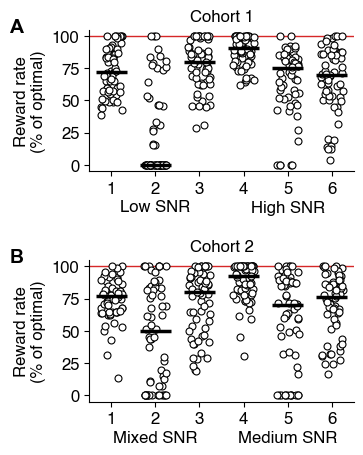

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure02_S01.pdf (+ .png)


In [7]:
from matplotlib import gridspec

WID = 8.5
HTS = [4.0, 4.0]
PSH = 2.5

Y_PAD = 5  # axis padding beyond [0, 100] so clipped points show in full

# Block groups shown under the block numbers (raw block order: 1-3 then 4-6).
GROUP_LABELS = {"OL": ("Low SNR", "High SNR"), "MX": ("Mixed SNR", "Medium SNR")}

rng_jitter = np.random.default_rng(99)

fig_h = sum(HTS) + PSH * (len(HTS) - 1)
hspace = PSH / np.mean(HTS)

use_figure_style()
fig = plt.figure(figsize=(WID * CM, fig_h * CM))
gs = gridspec.GridSpec(
    2,
    1,
    figure=fig,
    hspace=hspace,
    left=0.18,
    right=0.97,
    bottom=0.07,
    top=0.97,
)
axs = [fig.add_subplot(gs[r]) for r in range(2)]


def plot_rr_panel(ax, perf, n_blocks, groups, title=""):
    for bi in range(n_blocks):
        col = perf[:, bi]
        valid = np.isfinite(col)
        if not valid.any():
            continue
        clipped = np.clip(col[valid], 0, 100)
        jx = (bi + 1) + rng_jitter.uniform(-0.25, 0.25, size=valid.sum())
        ax.plot(jx, clipped, **SUBJECT_MARKER)
        # Median of the unclipped values, drawn within [0, 100] % like the points.
        med = float(np.clip(np.nanmedian(col), 0, 100))
        ax.plot(
            [bi + 0.65, bi + 1.35], [med, med], "-", color=DATA_COLOR, linewidth=2.5, zorder=5, solid_capstyle="butt"
        )
    ax.axhline(100, color=OPTIMAL_COLOR, linestyle="-", linewidth=1, zorder=0)
    ax.set_xlim(0.5, n_blocks + 0.5)
    ax.set_ylim(-Y_PAD, 100 + Y_PAD)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.set_xticks(range(1, n_blocks + 1))
    # Group labels under blocks 1-3 and 4-6, below the tick labels.
    for xc, lab in zip((2, 5), groups):
        ax.text(xc, -0.2, lab, transform=ax.get_xaxis_transform(), ha="center", va="top")
    ax.set_ylabel("Reward rate\n(% of optimal)")
    ax.set_title(title)
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)


plot_rr_panel(axs[0], ol_perf, 6, GROUP_LABELS["OL"], title="Cohort 1")
plot_rr_panel(axs[1], mx_perf, 6, GROUP_LABELS["MX"], title="Cohort 2")

add_panel_label(axs[0], "A", dx=-0.3)
add_panel_label(axs[1], "B", dx=-0.3)

out = FIGURES_DIR / "Figure02_S01.pdf"
fig.savefig(out, dpi=300, bbox_inches="tight")
fig.savefig(out.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved {out} (+ .png)")